# Segmentação de Imagens Acústicas de Poço sem *Ground Truth* (WAID)

**ELE2346 – Deep Learning** · Mestrado em Engenharia Elétrica (Sistemas Inteligentes) · PUC-Rio · 2026.2
Autor: Jorge Alberto Avelino de Souza

**Notebook 03 – CNN rasa e U-Net de referência (Fase 2).** Dados: WAID (PETROBRAS, CC BY 4.0), 5 poços.

## Fase 2 – CNN rasa e U-Net de referência
Treino com pseudo-rótulos de limiar (Otsu por poço), *leave-one-well-out*, avaliação por patch no conjunto anotado.

### 3.1 Ambiente: bibliotecas, Google Drive e GPU
Importando as bibliotecas, montando o Drive e instalando a biblioteca de segmentação.

In [1]:
# Importando as bibliotecas usadas no notebook
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from google.colab import drive

In [2]:
# Montando o Drive para uso dos arquivos WAID
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
# Instalando a biblioteca com a U-Net e o encoder ResNet18 (o Colab já traz o torch)
!pip install -q segmentation-models-pytorch

### 3.2 Configuração do projeto
Ajustando o caminho de busca, importando as funções de `src` e definindo os parâmetros dos treinos.

In [4]:
# Adicionando ao caminho de busca do Python a pasta que contém "src"
sys.path.insert(0, "/content/drive/MyDrive/waid")

# Importando as constantes e as funções do projeto
from src.config import POCOS, NPY_DIR, CARAC_DIR, ANOT_DIR, RES_DIR, ALTURA_PATCH
from src.labels.limiares import limiar_otsu_poco
from src.data.dataset_patches import carregar_imagens, excluir_sobrepostos, DatasetPatches
from src.train.treino import CFG_PADRAO, executar_fold, rodar_lowo
from src.eval.patches import avaliar_modelos, comparar_pareado

# Escolhendo o dispositivo (GPU, se houver)
DISP = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("dispositivo:", DISP, torch.cuda.get_device_name(0) if DISP.type == "cuda" else "")

# Definindo os parâmetros dos treinos (3 sementes, definidas após o teste de tempo)
CFG = dict(CFG_PADRAO, epocas=10)
MODELOS = ["cnn_rasa", "unet_resnet18"]
SEMENTES = [0, 1, 2]
print(CFG)

dispositivo: cuda Tesla T4
{'epocas': 10, 'lr': 0.001, 'lote': 16, 'paciencia': 4, 'deslocar': True, 'pretreino': True, 'altura': 256, 'val_cada': 2}


### 3.3 Dados: imagens, pseudo-rótulos e patches de treino
Carregando as imagens na memória, calculando o limiar de Otsu de cada poço e tirando do treino os patches que se sobrepõem aos anotados.

In [5]:
# Carregando as imagens normalizadas dos 5 poços na memória
imagens = carregar_imagens(NPY_DIR, POCOS)

# Calculando o limiar de Otsu de cada poço (pseudo-rótulo: pixel abaixo do limiar = feição escura)
limiares = {}
for p in POCOS:
    excl = np.load(f"{NPY_DIR}/{p}_excluir_rs.npy")
    limiares[p] = limiar_otsu_poco(imagens[p], excl)
print({p: round(v, 3) for p, v in limiares.items()})

# Lendo o índice de patches e as anotações; tirando do treino os patches que se sobrepõem aos anotados
indice = pd.read_csv(f"{CARAC_DIR}/patches_indice.csv")
anot = pd.read_csv(f"{ANOT_DIR}/anotacoes.csv")
indice_treino = excluir_sobrepostos(indice, anot, ALTURA_PATCH)
print(len(indice), "patches válidos;", len(indice_treino), "para treino e validação")
print(indice_treino.groupby("poco").size().to_string())

{'antilope25': 0.541, 'antilope37': 0.623, 'botorosa47': 0.67, 'coala88': 0.682, 'tatu22': 0.76}
3465 patches válidos; 3227 para treino e validação
poco
antilope25    801
antilope37    629
botorosa47    569
coala88       636
tatu22        592


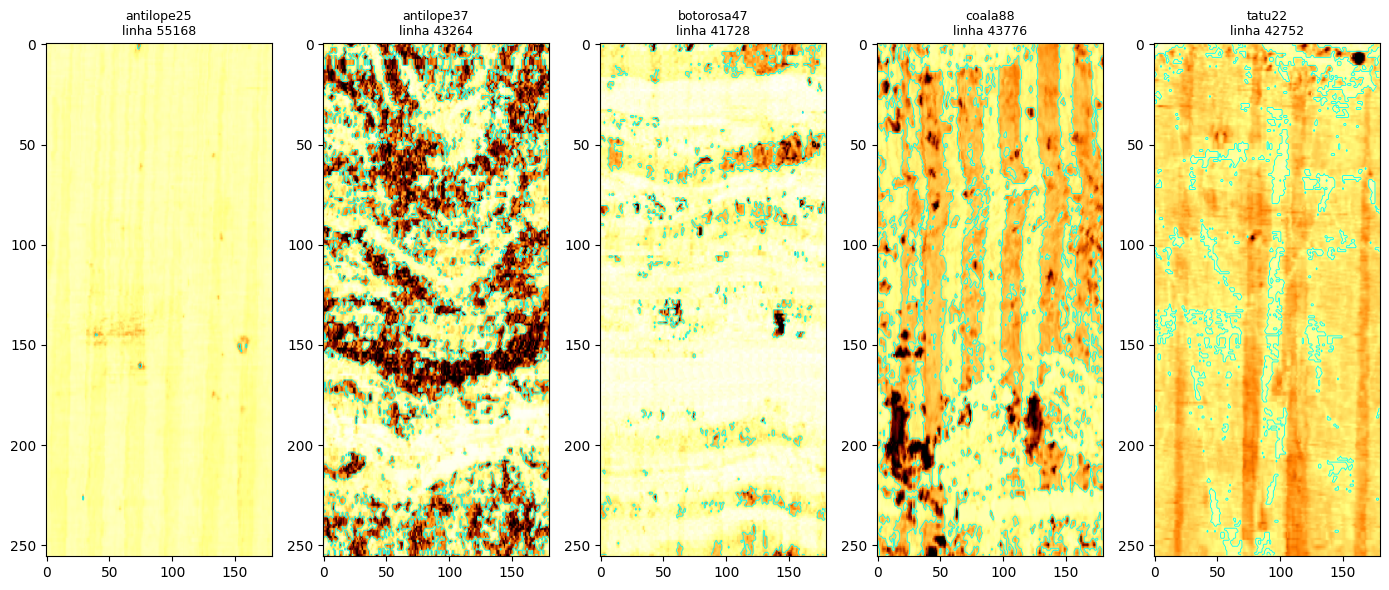

In [6]:
# Conferindo visualmente o pseudo-rótulo em 1 patch por poço (imagem e contorno do pseudo-rótulo)
fig, eixos = plt.subplots(1, 5, figsize=(14, 6))
for ax, p in zip(eixos, POCOS):
    r = indice_treino[indice_treino.poco == p].iloc[len(indice_treino[indice_treino.poco == p]) // 2]
    x = np.asarray(imagens[p][int(r.linha_ini):int(r.linha_ini) + ALTURA_PATCH], dtype=np.float32)
    ax.imshow(x, aspect="auto", cmap="afmhot", vmin=0, vmax=1)
    ax.contour(x < limiares[p], levels=[0.5], colors="cyan", linewidths=0.6)
    ax.set_title(f"{p}\nlinha {int(r.linha_ini)}", fontsize=9)
fig.tight_layout()
plt.show()

### 3.4 Teste rápido de tempo
Treinando 2 épocas em 1 *fold* (teste no coala88, validação no tatu22) para estimar o tempo total. O tempo decide quantas sementes e ablações cabem no cronograma.

In [7]:
# Treinando 2 épocas de cada modelo em 1 fold e estimando o tempo total (5 folds × sementes × épocas)
cfg_teste = dict(CFG, epocas=2, val_cada=1)
for m in MODELOS:
    _, res, hist = executar_fold(m, "coala88", "tatu22", 0, imagens, indice_treino, anot,
                                 limiares, cfg_teste, DISP)
    s_ep = hist.segundos.mean()
    print(f"{m}: {s_ep:.1f} s por época; fold completo (2 épocas + avaliação): {res['segundos']} s")
    print(f"  estimativa para {CFG['epocas']} épocas × 5 folds × {len(SEMENTES)} semente(s): "
          f"{s_ep * CFG['epocas'] * 5 * len(SEMENTES) / 60:.1f} min")

cnn_rasa: 8.4 s por época; fold completo (2 épocas + avaliação): 26.5 s
  estimativa para 10 épocas × 5 folds × 3 semente(s): 21.1 min


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

unet_resnet18: 12.2 s por época; fold completo (2 épocas + avaliação): 34.5 s
  estimativa para 10 épocas × 5 folds × 3 semente(s): 30.6 min


### 3.5 Treino: *leave-one-well-out*
Treinando cada modelo em 3 poços, validando em 1 e testando no restante. Cada *fold* é salvo em `results/modelos/`; se o Colab cair, executar de novo continua de onde parou.

In [8]:
# Rodando o leave-one-well-out (5 folds por modelo e semente)
escores, resumos = rodar_lowo(MODELOS, SEMENTES, POCOS, imagens, indice_treino, anot, limiares,
                              CFG, DISP, f"{RES_DIR}/modelos")
print(resumos.groupby("modelo")[["epocas_feitas", "melhor_dice_val", "dice_pseudo_teste", "segundos"]].mean().round(3))

               epocas_feitas  melhor_dice_val  dice_pseudo_teste  segundos
modelo                                                                    
cnn_rasa                10.0            0.691              0.677    57.900
unet_resnet18           10.0            0.666              0.625   114.267


### 3.6 Avaliação por patch
Comparando os modelos no conjunto anotado (AUC com intervalo de confiança por *bootstrap*; F1 com o corte escolhido nos outros poços) e com os *baselines* de limiar (seção 2.12 do notebook 02).

In [9]:
# Avaliando os modelos contra as decisões "feição clara" e "sem feição" (todos os folds juntos)
por_semente, resumo = avaliar_modelos(escores, "score_soft")
escores.to_csv(f"{RES_DIR}/modelos_escores.csv", index=False)
por_semente.to_csv(f"{RES_DIR}/modelos_patches.csv", index=False)
print(por_semente.to_string(index=False))
print()
print(resumo)

# Mostrando os baselines de limiar para comparação, se a seção 2.12 já foi executada
arq = f"{RES_DIR}/baselines_limiar_patches.csv"
if os.path.exists(arq):
    print()
    print(pd.read_csv(arq)[["metodo", "n", "auc", "ic95_baixo", "ic95_alto", "f1_lowo", "precisao", "revocacao"]].to_string(index=False))

       modelo  semente  n   auc  ic95_baixo  ic95_alto  f1_lowo  precisao  revocacao
     cnn_rasa        0 71 0.807       0.671      0.916    0.898     0.841      0.964
     cnn_rasa        1 71 0.780       0.664      0.883    0.804     0.789      0.818
     cnn_rasa        2 71 0.794       0.683      0.893    0.814     0.793      0.836
unet_resnet18        0 71 0.800       0.677      0.903    0.814     0.793      0.836
unet_resnet18        1 71 0.815       0.693      0.914    0.829     0.821      0.836
unet_resnet18        2 71 0.818       0.695      0.919    0.891     0.828      0.964

                 auc        f1_lowo        precisao        revocacao       
                mean    std    mean    std     mean    std      mean    std
modelo                                                                     
cnn_rasa       0.794  0.014   0.839  0.052    0.808  0.029     0.873  0.080
unet_resnet18  0.811  0.010   0.845  0.041    0.814  0.019     0.879  0.074

    metodo  n   auc  ic

### 3.7 Comparação pareada com o limiar de Otsu
Comparando cada modelo com o Otsu nos mesmos 71 patches. O *bootstrap* pareado sorteia patches inteiros e mede a diferença de AUC (modelo menos Otsu). Se o intervalo não incluir zero, a diferença é detectável. Também compara dois escores do modelo: a probabilidade média (`score_soft`) e a fração de pixels preditos (`score`).

In [10]:
# Lendo os escores dos limiares (seção 2.12) e comparando cada modelo com o Otsu nos mesmos patches
base = pd.read_csv(f"{RES_DIR}/baselines_limiar_escores.csv")
pareado = comparar_pareado(escores, base, "score_soft", "otsu")
print(pareado.to_string(index=False))

# Comparando os dois escores do modelo (probabilidade média × fração de pixels preditos)
for col in ["score_soft", "score"]:
    _, res_col = avaliar_modelos(escores, col)
    print()
    print(col)
    print(res_col[["auc", "f1_lowo"]])

       modelo  n  auc_modelo  auc_base  diferenca  ic95_baixo  ic95_alto
     cnn_rasa 71       0.780     0.932     -0.152      -0.264     -0.069
unet_resnet18 71       0.811     0.932     -0.120      -0.210     -0.048

score_soft
                 auc        f1_lowo       
                mean    std    mean    std
modelo                                    
cnn_rasa       0.794  0.014   0.839  0.052
unet_resnet18  0.811  0.010   0.845  0.041

score
                 auc        f1_lowo       
                mean    std    mean    std
modelo                                    
cnn_rasa       0.816  0.008   0.827  0.010
unet_resnet18  0.819  0.011   0.850  0.051
